# Vehicule Routing Problem (VRP)

Los problemas de enrutamiento de vehiculos o vehicule routing problem, es un problema de optimización combinatorial y de programación entera de complejidad alta que responde a la pregunta: **¿Cuál es el conjunto óptimo de rutas que una flota de vehículos debe recorrer para entregar servicios a un conjunto dado de clientes?**. El problema es una generalización del problema del vendedor ambulante, o travelling salesman problem (TSP), que es el caso donde solo se requiere una ruta para visitar todos los destinos y la problematica es encontrar el orden óptimo de visita. El VRP, aparte de buscar el orden óptimo de visita de los destinos por cada ruta, busca múltiples rutas para ser llevadas a cabo por muchos "vendedores" o vehiculos. En términos de complejidad computacional, tanto el VRP como el TSP son NP-hard, esto quiere decir, evitando las definiciones matemáticas, que son problemas especialmente dificiles de resolver y es posible que encontrar soluciones exactas sea prácticamente imposible en tiempos de años, décadas o incluso siglos(sin exagerar), por lo que es recomendable aproximar soluciones, sobre todo con VRP de gran tamaño.

Por facilidad de implementación, se usa la librería Pyvrp. Esta librería nos permite crear un modelo de VRP (Vehicule Routing Problem) y solucionarlo a través de un Algoritmo Genético Híbrido con Búsqueda Local (HGS). Este Algoritmo funciona, a grandes rasgos, creando aleatoriamente muchas posibles soluciones al problema, denominadas población, de las cuales se seleccionan las dos mejores tomando en cuenta la función objetivo a optimizar (en este caso costo o distancia recorrida por los vehículos). Estas dos mejores soluciones se denominan "padres" y son "cruzadas" o mezcladas para generar otra solucion denominada "descendencia" que hereda aspectos de sus soluciones padres (por ejemplo, mantener la primera parte de las rutas de uno de sus padres, y el resto de su segundo padre). Luego, este descendiente es "educado", esto consiste en que es sujeto a un proceso de mejoramiento llamado búsqueda local, que cambia aspectos de esta posible solución para que su desempeño comparado a la función objetivo mejore(por ejemplo, intercambiar el orden de visita de los distintos destinos, visitando un destino más, entre otras opciones). Después de este proceso, el descendiente se incorpora a la población y se repite el proceso, seleccionando otros padres, generando descendencia y educandola, hasta obtener una solución que sea lo suficientemente satisfactoria.

# Implementación

La librería PyVRP nos permite crear un modelo de VRP que podemos personalizar, agregando demanda para los destinos, capacidad a los vehiculos, ventanas de tiempo para las visitas de los vehiculos a los destinos, entre otras características.

Para revisar la documentación de la Librería: [Entrar aquí](https://pyvrp.readthedocs.io/en/stable/index.html)


# Nodos

A continuación se crea el modelo con la clase __Model()__, y se procede a agregar los nodos (puntos de abastecimiento y destinos).

El método __.add_depot__ agrega un punto de abastecimiento u origen para los vehículos del modelo, teniendo como algunos de sus parámetros lo siguiente:

1. Coordenadas **x,y** para el plano cartesiano, la ubicación en el mapa del nodo en base a un punto de referencia.
1. Una ventana de tiempo **tw_early** y **tw_late** expresada en minutos. **tw_early** representa la hora de apertura y **tw_late** la hora de cierre. El tiempo se expresa en minutos y en base a un tiempo de referencia. En este ejemplo, 0 representa las 00:00 horas, 420 representa 07:00 horas, 720 son las 12:00, 900 son las 15:00, 1200 las 20:00, 1440 las 24:00 y así.
1. Un nombre **name** para identificar cada nodo.

El método **.add_client** agrega un destino o cliente, un nodo al que el vehículo presta servicio, en este caso, descarga. Comparte los parámetros del método anterior además de los siguientes:

1. Una demanda **delivery** es la demanda que cada cliente o destino requiere. En este ejemplo, los litros de combustible que la estacion de servicio necesita para funcionar correctamente.
1. Un tiempo de servicio **service_duration** en este ejemplo es el tiempo que tarda un vehiculo en atender a la estacion de servicio. Es decir, descarga de combustible y bienes, entre otras cosas.

In [1]:
#Para el código es necesario instalar la librería pyvrp
#%pip install pyvrp


In [ ]:

import numpy as np
from pyvrp import Model
from pyvrp . stop import MaxRuntime
from pyvrp.plotting import plot_coordinates,plot_solution,plot_diversity, plot_objectives, plot_runtimes, plot_route_schedule


m=Model() #Creación del modelo

m.add_depot(x=2, y=0, tw_early=420, tw_late= 900, name= 'abast_1') #origen/abastecimiento

m.add_depot(x=2, y=-4, tw_early=480, tw_late= 960, name= 'abast_2')

m.add_client(x=0, y=0, delivery=4, tw_early=480, tw_late=720, service_duration=25, name='destino_1') #entrega

m.add_client(x=4, y=0, delivery=3, tw_early=540, tw_late=780, service_duration=20, name='destino_2')

m.add_client(x=4, y=-5, delivery=5, tw_early=600, tw_late=840, service_duration=30, name='destino_3')



# Vehiculos

Es también necesario agregar al modelos los vehículos. Estos pueden variar en capacidad, punto de origen, u otras características, que nos permiten agruparlos por tipo. En este ejemplo, identificamos dos tipos de vehículos con distinta capacidad.

Se agregan al modelo con el método **.add_vehicle_type** que cuenta con, aunque no esta limitado a, los siguiente parámetros:

1. Una capacidad de carga **capacity** que representa el cargamento máximo del tipo de vehículo.
2. Un número de disponibilidad **num_available** como la cantidad de vehículos disponibles por tipo.
3. Nodos de origen y final **start_depot** y **end_depot**, que son los puntos de abastecimiento donde el tipo de vehículo comienza su ruta, y dónde debe terminar la ruta. En este ejemplo, todos los vehículos comienzan y terminan en el primer puntos de abastecimiento
4. Nodos de recarga **reload_depots** que son los puntos de abasticimiento en los cuales el tipo de vehículo puede reabastecerse en medio de su ruta para recuperar cargamento y seguir su ruta. En este ejemplo, ambos puntos de abastecimiento son nodos de recarga para ambos tipos de vehículos.

In [ ]:


m.add_vehicle_type(capacity=5, num_available=1, start_depot=m.locations[0], end_depot=m.locations[0], reload_depots=[m.locations[0], m.locations[1]], name='camion_1')

m.add_vehicle_type(capacity=8, num_available=1, start_depot=m.locations[0], end_depot=m.locations[0], reload_depots=[m.locations[0], m.locations[1]], name='camion_2')

# Matriz de distancias

Para representar la distancia entre todos los nodos existe la matriz de distancias, donde la fila (i) representa un nodo de origen y la columna (j) un nodo de destino, y la componente (i,j) de la matriz representa la distancia de un viaje desde el nodo (i) al nodo (j). Es interesante destacar que la diagonal es 0, ya que representaría un viaje desde y hasta el mismo nodo, por lo que la distancia de ese viaje sería 0. 

En este ejemplo, la distancia de un viaje desde el nodo (i) al nodo (j) es la misma a la del viaje desde el nodo (j) al nodo (i), por lo que se dice que es simétrico. Es común que este no sea el caso.

In [ ]:

Distancias=[ 
    [0, 20, 5, 6, 35],
    [20, 0, 30, 22, 8],
    [5, 30, 0, 13, 45],
    [6, 22, 13, 0, 30],
    [35, 8, 45, 30, 0]
]


# Aristas o caminos

Se agregan los posibles caminos usando el método **.add_edge**. Este método añade una conexión entre un nodo de origen a otro de destino, con una distancia. En este ejemplo, usamos la matriz de distancias para rellenar todos posibles caminos. También es posible usar las coordenadas para calcular dicha distancia a través de una función de distancia Euclidiana, distancia Manhatann, distancia Minkowski, u otras.

In [ ]:
for frm_idx, frm in enumerate(m.locations):
    for to_idx, to in enumerate(m.locations):
        m.add_edge(frm, to, distance=Distancias[frm_idx][to_idx])

# La solución

Ya con toda esta implementación, podemos usar la librería para darle solución al problema.
El método solve entrega una solución. En este caso, le pedimos al algoritmo detenerse después de un segundo, y usamos una semilla para los ámbitos aleatorios.

In [7]:
#Solución según la librería
res = m. solve ( stop = MaxRuntime (1) , seed = 3) # un segundo


PyVRP v0.11.3

Solving an instance with:
    2 depots
    3 clients
    2 vehicles (2 vehicle types)

                  |       Feasible        |      Infeasible
    Iters    Time |   #      Avg     Best |   #      Avg     Best
H     500      1s |  32       76       74 |  63       76       74

Search terminated in 1.00s after 926 iterations.
Best-found solution has cost 74.

Solution results
    # routes: 2
     # trips: 3
   # clients: 3
   objective: 74
    distance: 74
    duration: 75
# iterations: 926
    run-time: 1.00 seconds



# Explicando la solución
La solución que nos entrega la librería nos indica primero una visión general sobre los parámetros del modelo, puntos de abasticimiento, destinos, y vehículos. 

Luego nos entrega una tabla que expone la cantidad de iteraciones que realiza (Iters), el tiempo que transcurrió (Time), y nos muestra una población factible (feasible; que respetan las restricciones impuestas al modelo) e infactible (infeasible; que no respetan las restricciones) de soluciones generadas por el algoritmo genético. Nos indica cuánta población hay(#), la evaluación promedio de la función objetivo de la población (Avg), y la mejor evaluación que se obtuvo por una solución particular dentro de esa población (Best).

In [8]:
print (res)

Solution results
    # routes: 2
     # trips: 3
   # clients: 3
   objective: 74
    distance: 74
    duration: 75
# iterations: 926
    run-time: 1.00 seconds

Routes
------
Route #1: 2
Route #2:  | 4 3



# Resultado

El resultado explicado nos indica, respecto a la mejor solución obtenida:
1. Cuántas rutas son (# routes; los traye tos a realizar por los vehículos)
2. Los viajes (# trips; los desplazamientos entre nodos)
3. El número de destinos o clientes (# clients)
4. El valor del la función objetivo a minimizar  (objective)
5. La distancia total que recorren los vehículos (distance)
6. La duración total de los viajes de los vehículos (duration; esto es por defecto, es posible agregar duraciones personalizadas a los viajes modificando las aristas o caminos del modelo)
7. Cuantas iteraciones se realizaron (# iterations)
8. El tiempo que el algoritmo se ejecutó (run-time)

9. Las Rutas para los vehículos (Routes)
    - Estas rutas siguen el orden de los vehículos, la ruta 1 es para el vehículo 1, la ruta 2 para el vehículo 2 y así.
    - Las rutas indican el orden de visita de los nodos de izquierda a derecha.
    - Las | de la ruta indica el movimiento a un nodo de reabastecimiento.

En este ejemplo, el primer vehículo va desde el origen al destino 2 y luego vuelve al origen. El segundo vehículo viaja al segundo punto de abastecimiento, luego viaja al destino 4, después al destino 3 y finaliza volviendo al punto de abastecimiento de origen.

Abajo se exponen gráficos que ayuden a la visualización de la solución.

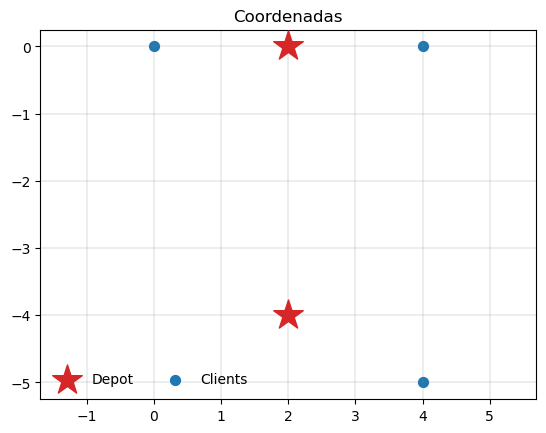

In [9]:
plot_coordinates(data=m.data(),title='Coordenadas') #Gráfica de coordenadas

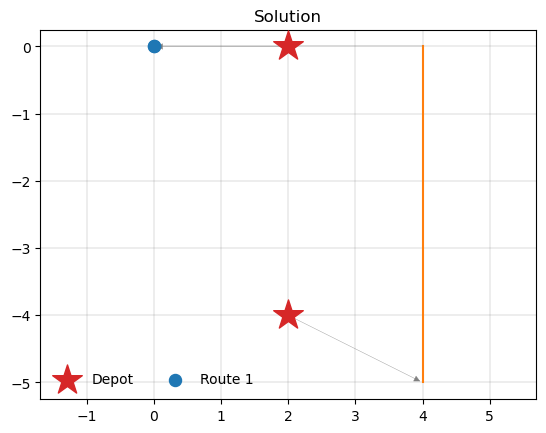

In [10]:
plot_solution(res.best, data=m.data()) #Gráfica de rutas

# Diversidad
La diversidad explica que tan distintos son las soluciones presentes en cada una de las poblaciones del algoritmo genético. Un número bajo quiere decir que las soluciones son muy homogéneas, es decir, muy parecidas entre sí.
Esto es importante para mantener una buena búsqueda para las soluciones.

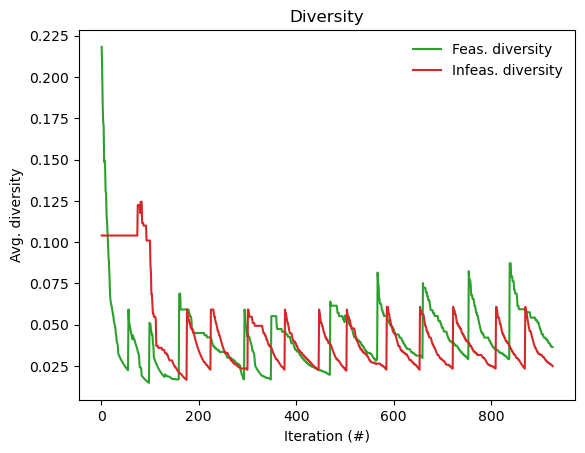

In [11]:
plot_diversity(res) #Gráfico de Diversidad 

# Función objetivo

El valor a minimizar, que se busca mejorar con cada iteración, ojalá respetando las restricciones impuestas al modelo.

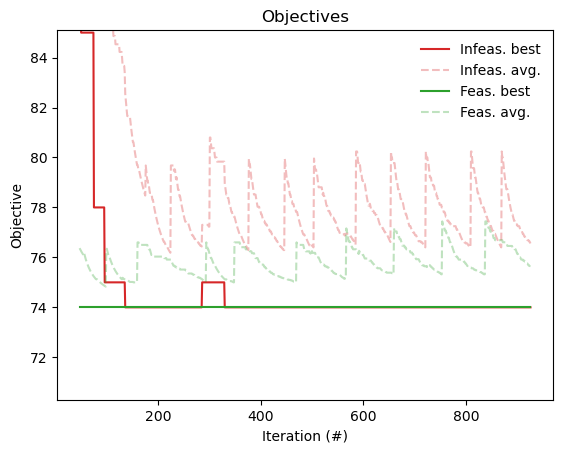

In [12]:
plot_objectives(res) #Gráfico de Función Objetivo

# Tiempos de ejecución
El tiempo que demora realizar las iteraciones, comparado con le tiempo promedio.

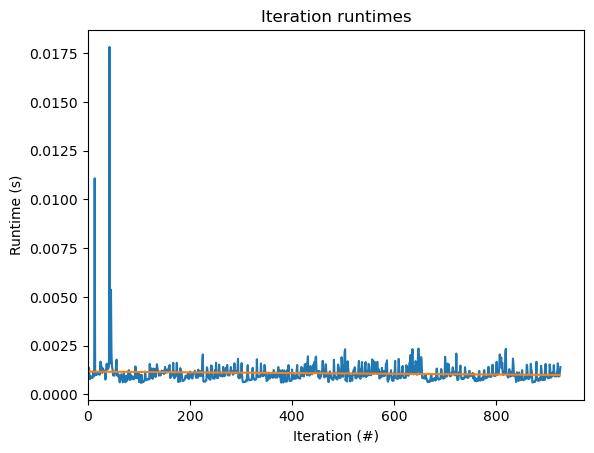

In [13]:
plot_runtimes(res) #Gráfico de tiempos de ejecución